In [1]:
!unzip "construction safety.v1i.yolov8.zip" -d /content/dataset


unzip:  cannot find or open construction safety.v1i.yolov8.zip, construction safety.v1i.yolov8.zip.zip or construction safety.v1i.yolov8.zip.ZIP.


# DATASETS USED FOR IndustrialAI:-

we have used multiple datasets but primarily two which are as below:-

PartA - **smoke_detection_iot.csv (Kaggle)**

PartB - **Construction safety.v1.yolov8 (Roboflow)**

Also we will be processing and generating ml models for partA and partB respectively.

**Part A — Environmental Sensor ML**

1. Importing required libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

2. Uploading sensor dataset

In [3]:
uploaded = files.upload()

csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Please upload the sensor dataset CSV file.")

df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully.")

Saving smoke_detection_iot.csv to smoke_detection_iot.csv
Dataset loaded successfully.


3. Understanding dataset

In [4]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (62630, 16)

Columns:
['Unnamed: 0', 'UTC', 'Temperature[C]', 'Humidity[%]', 'TVOC[ppb]', 'eCO2[ppm]', 'Raw H2', 'Raw Ethanol', 'Pressure[hPa]', 'PM1.0', 'PM2.5', 'NC0.5', 'NC1.0', 'NC2.5', 'CNT', 'Fire Alarm']


,Unnamed: 0,UTC,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,CNT,Fire Alarm
0,0,1654733331,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0,0
1,1,1654733332,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,1,0
2,2,1654733333,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,2,0
3,3,1654733334,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,3,0
4,4,1654733335,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,4,0



Missing values:
Unnamed: 0        0
UTC               0
Temperature[C]    0
Humidity[%]       0
TVOC[ppb]         0
eCO2[ppm]         0
Raw H2            0
Raw Ethanol       0
Pressure[hPa]     0
PM1.0             0
PM2.5             0
NC0.5             0
NC1.0             0
NC2.5             0
CNT               0
Fire Alarm        0
dtype: int64


4. cleaning and Preprocessing

In [5]:
target_col = next(
    (col for col in df.columns if str(col).strip().lower() == "fire alarm"),
    None
)

if target_col is None:
    raise ValueError("The Fire Alarm target column was not found.")

excluded_cols = [
    col for col in df.columns
    if str(col).strip().lower() in {
        "utc", "cnt", "timestamp", "time", "datetime"
    } or str(col).strip().lower().startswith("unnamed")
]

X = df.drop(
    columns=[target_col] + excluded_cols,
    errors="ignore"
).apply(pd.to_numeric, errors="coerce")

X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna(axis=1, how="all")

y = pd.to_numeric(df[target_col], errors="coerce")

valid_rows = y.notna() & X.notna().all(axis=1)

X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Features:", X.columns.tolist())

Feature shape: (62630, 12)
Target shape: (62630,)
Features: ['Temperature[C]', 'Humidity[%]', 'TVOC[ppb]', 'eCO2[ppm]', 'Raw H2', 'Raw Ethanol', 'Pressure[hPa]', 'PM1.0', 'PM2.5', 'NC0.5', 'NC1.0', 'NC2.5']


5. checking target distribution

Fire Alarm
1    44757
0    17873
Name: count, dtype: int64

Class percentages:
Fire Alarm
1    71.46
0    28.54
Name: proportion, dtype: float64


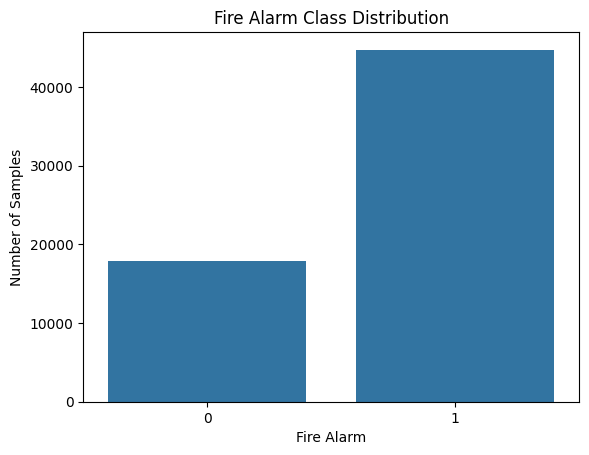

In [6]:
print(y.value_counts())

print("\nClass percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

sns.countplot(x=y)
plt.title("Fire Alarm Class Distribution")
plt.xlabel("Fire Alarm")
plt.ylabel("Number of Samples")
plt.show()

6. Data Splitting

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 50104
Testing samples: 12526


7. Model Training

In [8]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced_subsample",
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


8. evaluating model

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3575
           1       1.00      1.00      1.00      8951

    accuracy                           1.00     12526
   macro avg       1.00      1.00      1.00     12526
weighted avg       1.00      1.00      1.00     12526



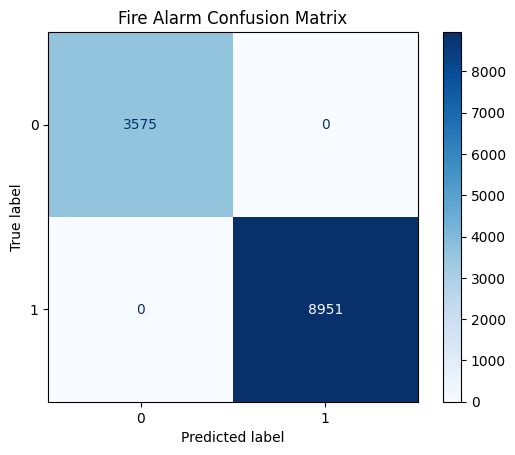

In [9]:
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Fire Alarm Confusion Matrix")
plt.show()

9. Feature importance

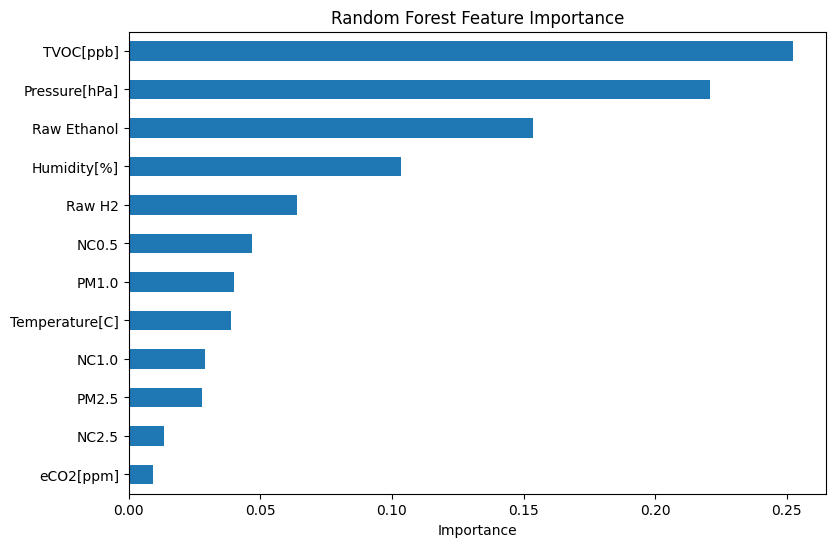

In [10]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values()

importance.plot(kind="barh", figsize=(9, 6))

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

10. Model saving

In [11]:
model_bundle = {
    "model": model,
    "feature_names": X.columns.tolist(),
    "target_name": target_col,
    "classes": sorted(y.unique().tolist())
}

joblib.dump(model_bundle, "/content/industrialguard_sensor_model.joblib")

print("Sensor model saved successfully.")

Sensor model saved successfully.


11. Downloading model

In [12]:
files.download("/content/industrialguard_sensor_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Part B — Computer Vision**

1. Installing computer Vision libraries

In [13]:
!pip -q install ultralytics pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 78.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.6 MB/s eta 0:00:00


2. uploading PartB dataset

In [14]:
uploaded = files.upload()

zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload the PPE dataset ZIP file.")

zip_path = zip_files[0]
print("Uploaded:", zip_path)

Saving construction safety.v1i.yolov8.zip to construction safety.v1i.yolov8.zip
Uploaded: construction safety.v1i.yolov8.zip


3. Extracting dataset

In [15]:
import zipfile
from pathlib import Path

dataset_dir = Path("/content/ppe_dataset")
dataset_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(dataset_dir)

yaml_files = list(dataset_dir.rglob("data.yaml"))

if not yaml_files:
    raise FileNotFoundError("Could not find data.yaml in the dataset.")

data_yaml_path = yaml_files[0]

print("Dataset configuration:", data_yaml_path)

Dataset configuration: /content/ppe_dataset/construction safety.v1i.yolov8/data.yaml


4. Inspecting

In [16]:
import yaml

dataset_config = yaml.safe_load(data_yaml_path.read_text())

print("Classes:", dataset_config.get("names"))
print("Number of classes:", dataset_config.get("nc"))
print("Training path:", dataset_config.get("train"))
print("Validation path:", dataset_config.get("val"))
print("Test path:", dataset_config.get("test"))

Classes: ['helmet', 'no-helmet', 'no-vest', 'person', 'vest']
Number of classes: 5
Training path: ../train/images
Validation path: ../valid/images
Test path: ../test/images


5. Fixing ds paths

In [17]:
train_dirs = list(dataset_dir.rglob("train/images"))
valid_dirs = list(dataset_dir.rglob("valid/images"))
valid_dirs += list(dataset_dir.rglob("val/images"))

if not train_dirs or not valid_dirs:
    raise FileNotFoundError("Could not find train/images and valid/images or val/images.")

train_images_dir = train_dirs[0]
dataset_root = train_images_dir.parents[1]

valid_images_dir = next(
    path for path in valid_dirs
    if path.parents[1] == dataset_root
)

test_images_dir = dataset_root / "test" / "images"

dataset_config["path"] = str(dataset_root)
dataset_config["train"] = str(train_images_dir.relative_to(dataset_root))
dataset_config["val"] = str(valid_images_dir.relative_to(dataset_root))

if test_images_dir.exists():
    dataset_config["test"] = str(test_images_dir.relative_to(dataset_root))
else:
    dataset_config.pop("test", None)

local_yaml = Path("/content/industrialguard_ppe.yaml")
local_yaml.write_text(yaml.safe_dump(dataset_config, sort_keys=False))

print(local_yaml.read_text())

train: train/images
val: valid/images
test: test/images
nc: 5
names:
- helmet
- no-helmet
- no-vest
- person
- vest
roboflow:
  workspace: anjali-kumari-vrqdi
  project: construction-safety-gsnvb-puk4o-k1hjc
  version: 1
  license: CC BY 4.0
  url: https://app.roboflow.com/anjali-kumari-vrqdi/construction-safety-gsnvb-puk4o-k1hjc/1
path: /content/ppe_dataset/construction safety.v1i.yolov8



6. Checking files

In [18]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

train_images = [
    path for path in train_images_dir.iterdir()
    if path.suffix.lower() in image_extensions
]

valid_images = [
    path for path in valid_images_dir.iterdir()
    if path.suffix.lower() in image_extensions
]

print("Training images:", len(train_images))
print("Validation images:", len(valid_images))

if test_images_dir.exists():
    test_images = [
        path for path in test_images_dir.iterdir()
        if path.suffix.lower() in image_extensions
    ]
    print("Test images:", len(test_images))

Training images: 997
Validation images: 119
Test images: 90


7. Loading and Training model

In [19]:
from ultralytics import YOLO

ppe_model = YOLO("yolov8n.pt")

training_results = ppe_model.train(
    data=str(local_yaml),
    epochs=30,
    imgsz=640,
    batch=8,
    patience=8,
    project="/content/industrialguard_runs",
    name="ppe_yolov8n",
    exist_ok=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/industrialguard_ppe.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0

8. Model Saving

In [20]:
best_model_path = Path(
    "/content/industrialguard_runs/ppe_yolov8n/weights/best.pt"
)

if not best_model_path.exists():
    raise FileNotFoundError("The best model weights were not found.")

best_model = YOLO(str(best_model_path))

print("Best PPE model loaded.")

Best PPE model loaded.


9. Model Evaluation

In [21]:
split_name = "test" if test_images_dir.exists() else "val"

metrics = best_model.val(
    data=str(local_yaml),
    split=split_name,
    imgsz=640
)

print("Precision:", round(float(metrics.box.mp), 4))
print("Recall:", round(float(metrics.box.mr), 4))
print("mAP50:", round(float(metrics.box.map50), 4))
print("mAP50-95:", round(float(metrics.box.map), 4))

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2564.8±805.1 MB/s, size: 126.0 KB)
val: Scanning /content/ppe_dataset/construction safety.v1i.yolov8/test/labels... 90 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 90/90 2.0Kit/s 0.0s
val: New cache created: /content/ppe_dataset/construction safety.v1i.yolov8/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.8it/s 3.4s
                   all         90        623      0.721       0.82      0.784      0.413
                helmet         82        195      0.792      0.938      0.915      0.495
             no-helmet         11         24      0.645      0.605      0.523      0.222
               no-vest         31         61      0.563      0.803      0.714      0.316
                pers

10. Model Testing


image 1/1 /content/ppe_dataset/construction safety.v1i.yolov8/test/images/ppe_0403_jpg.rf.42eaa189325630a8109e4544ef416adb.jpg: 640x448 1 helmet, 1 person, 2 vests, 10.3ms
Speed: 1.7ms preprocess, 10.3ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 448)


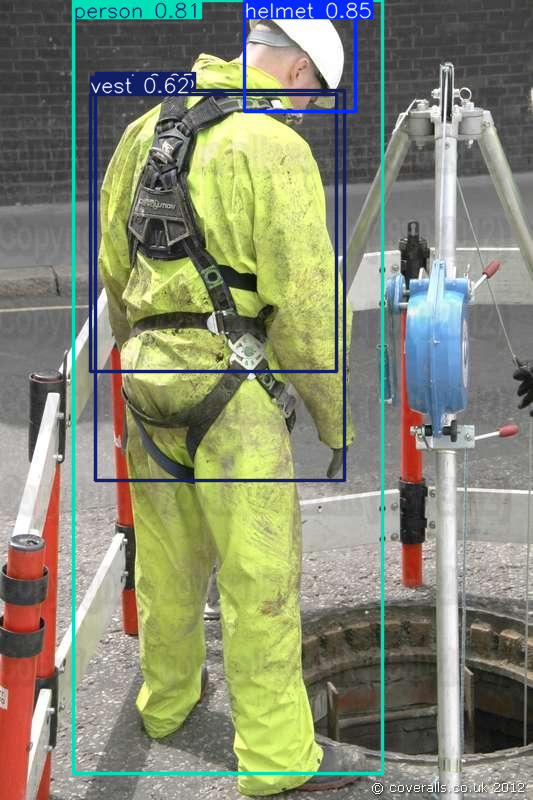

In [22]:
from PIL import Image
from IPython.display import display

if test_images_dir.exists() and any(test_images_dir.iterdir()):
    image_candidates = [
        path for path in test_images_dir.iterdir()
        if path.suffix.lower() in image_extensions
    ]
else:
    image_candidates = valid_images

image_path = image_candidates[0]

predictions = best_model.predict(
    source=str(image_path),
    conf=0.25,
    save=False
)

annotated_image = predictions[0].plot()

display(Image.fromarray(annotated_image[:, :, ::-1]))

In [23]:
files.download(str(best_model_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
from pathlib import Path

for p in Path("/content").rglob("best.pt"):
    print("Best model found:", p)

for p in Path("/content").rglob("last.pt"):
    print("Last checkpoint found:", p)

Best model found: /content/industrialguard_runs/ppe_yolov8n/weights/best.pt
Last checkpoint found: /content/industrialguard_runs/ppe_yolov8n/weights/last.pt


In [25]:
from google.colab import files

files.download("/content/industrialguard_runs/ppe_yolov8n/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>